# Exploration des données DVF

Premier notebook du projet : chargement des ventes immobilières de Paris et de la petite couronne (2021-2025), nettoyage, puis premières analyses des prix au m².

Les données doivent d'abord être téléchargées avec `python src/download_data.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))  # pour importer le dossier src/
from src.cleaning import load_raw, clean

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")

## Chargement

In [2]:
raw = load_raw()
print(f"{len(raw):,} lignes, {raw['id_mutation'].nunique():,} mutations")
raw.head()

1,289,626 lignes, 552,046 mutations


,id_mutation,date_mutation,nature_mutation,valeur_fonciere,code_postal,code_commune,nom_commune,code_departement,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude
0,2021-1682562,2021-01-05,Vente,1480000.0,75008,75108,Paris 8e Arrondissement,75,Appartement,111.0,5.0,NaN,2.320982,48.876954
1,2021-1682562,2021-01-05,Vente,1480000.0,75008,75108,Paris 8e Arrondissement,75,Dépendance,NaN,0.0,NaN,2.320982,48.876954
2,2021-1682562,2021-01-05,Vente,1480000.0,75008,75108,Paris 8e Arrondissement,75,Dépendance,NaN,0.0,NaN,2.320982,48.876954
3,2021-1682562,2021-01-05,Vente,1480000.0,75008,75108,Paris 8e Arrondissement,75,Dépendance,NaN,0.0,NaN,2.320982,48.876954
4,2021-1682563,2021-01-05,Vente,20000.0,75008,75108,Paris 8e Arrondissement,75,Dépendance,NaN,0.0,NaN,2.319574,48.878074


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1289626 entries, 0 to 1289625
Data columns (total 14 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   id_mutation                1289626 non-null  object 
 1   date_mutation              1289626 non-null  object 
 2   nature_mutation            1289626 non-null  object 
 3   valeur_fonciere            1276718 non-null  float64
 4   code_postal                1266390 non-null  object 
 5   code_commune               1289626 non-null  object 
 6   nom_commune                1289626 non-null  object 
 7   code_departement           1289626 non-null  object 
 8   type_local                 1178125 non-null  object 
 9   surface_reelle_bati        589756 non-null   float64
 10  nombre_pieces_principales  1177769 non-null  float64
 11  surface_terrain            233803 non-null   float64
 12  longitude                  1272524 non-null  float64
 13  latitude    

## Structure des données

Une mutation correspond à une vente. Mais une même vente peut être découpée en plusieurs lignes (l'appartement, la cave, le parking...) et chaque ligne reprend la valeur foncière totale. Calculer un prix au m² directement sur les lignes donnerait donc des résultats faux.

On regarde d'abord les types de locaux et le nombre de lignes par vente.

In [4]:
raw["type_local"].value_counts(dropna=False)

type_local
Dépendance                                  587552
Appartement                                 471135
NaN                                         111501
Local industriel. commercial ou assimilé     60684
Maison                                       58754
Name: count, dtype: int64

In [5]:
lignes_par_vente = raw.groupby("id_mutation").size()
lignes_par_vente.value_counts().head(10)

2     225036
1     202004
3      87093
4      22396
5       5418
6       2543
7       1206
8        862
9        553
10       467
Name: count, dtype: int64

## Nettoyage

Les règles sont dans `src/cleaning.py` :
- uniquement les ventes (pas les échanges ni les adjudications)
- uniquement les ventes d'un seul logement, appartement ou maison
- surface entre 9 et 500 m²
- prix au m² entre le 1er et le 99e percentile, par département et type de bien

In [6]:
df = clean(raw)
print(f"{len(df):,} ventes conservées ({len(df) / raw['id_mutation'].nunique():.0%} des mutations)")
df[["valeur_fonciere", "surface_reelle_bati", "nombre_pieces_principales", "prix_m2"]].describe()

368,501 ventes conservées (67% des mutations)


,valeur_fonciere,surface_reelle_bati,nombre_pieces_principales,prix_m2
count,3.685010e+05,368501.000000,368501.000000,368501.000000
mean,4.496740e+05,60.242469,2.767138,7587.575751
std,4.201506e+05,35.808202,1.363703,3555.544813
min,7.622500e+02,9.000000,0.000000,64.935065
25%,2.150000e+05,35.000000,2.000000,4780.219780
50%,3.330000e+05,54.000000,3.000000,7276.315789
75%,5.350000e+05,76.000000,4.000000,10000.000000
max,1.934600e+07,497.000000,78.000000,43376.681614


## Distribution des prix au m²

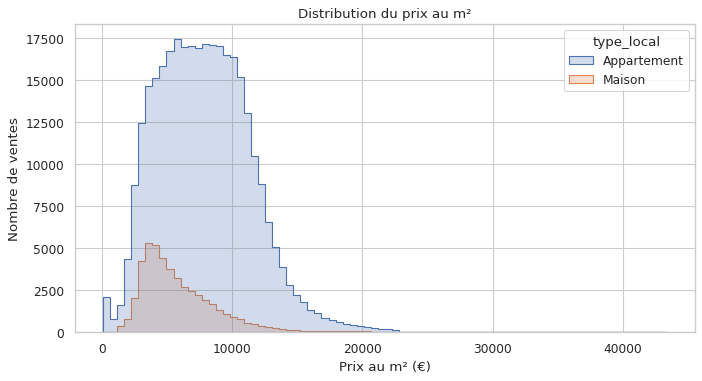

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x="prix_m2", hue="type_local", bins=80, element="step", ax=ax)
ax.set(title="Distribution du prix au m²", xlabel="Prix au m² (€)", ylabel="Nombre de ventes")
plt.savefig(FIG_DIR / "distribution_prix_m2.png", dpi=150, bbox_inches="tight")
plt.show()

## Prix médian par département

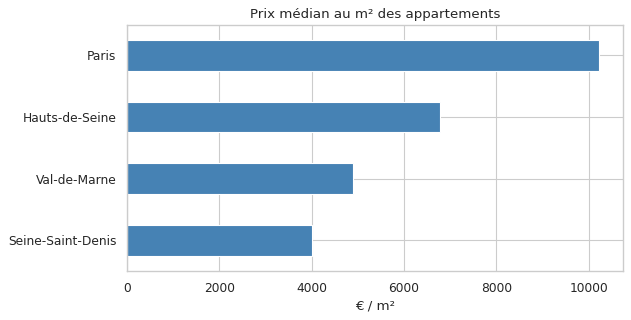

In [8]:
noms = {"75": "Paris", "92": "Hauts-de-Seine", "93": "Seine-Saint-Denis", "94": "Val-de-Marne"}
par_dep = (df[df["type_local"] == "Appartement"]
           .groupby("code_departement")["prix_m2"].median()
           .rename(index=noms).sort_values())

ax = par_dep.plot.barh(figsize=(8, 4), color="steelblue")
ax.set(title="Prix médian au m² des appartements", xlabel="€ / m²", ylabel="")
plt.savefig(FIG_DIR / "prix_median_departement.png", dpi=150, bbox_inches="tight")
plt.show()

## Évolution par année

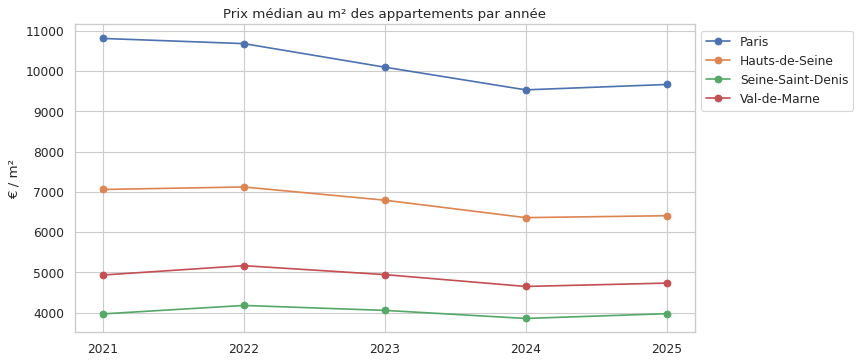

In [9]:
evolution = (df[df["type_local"] == "Appartement"]
             .groupby(["annee", "code_departement"])["prix_m2"].median()
             .unstack().rename(columns=noms))

ax = evolution.plot(marker="o", figsize=(10, 5))
ax.set(title="Prix médian au m² des appartements par année", xlabel="", ylabel="€ / m²")
ax.set_xticks(evolution.index)
ax.legend(title="", loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig(FIG_DIR / "evolution_prix.png", dpi=150, bbox_inches="tight")
plt.show()

## Paris, arrondissement par arrondissement

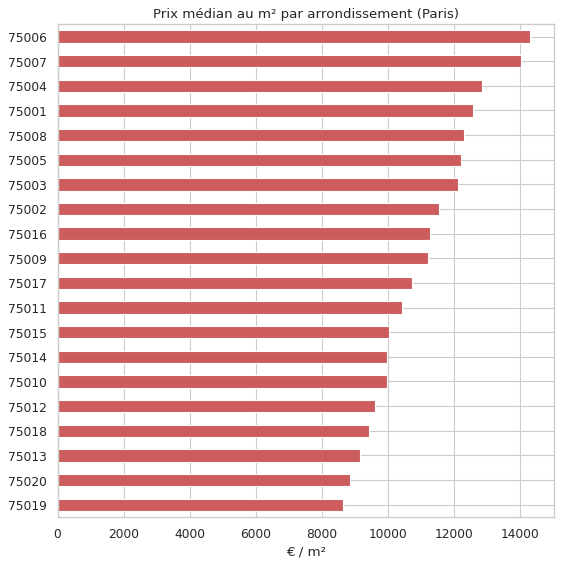

In [10]:
paris = df[(df["code_departement"] == "75") & (df["type_local"] == "Appartement")]
par_arr = paris.groupby("code_postal")["prix_m2"].median().sort_values()

ax = par_arr.plot.barh(figsize=(8, 8), color="indianred")
ax.set(title="Prix médian au m² par arrondissement (Paris)", xlabel="€ / m²", ylabel="")
plt.savefig(FIG_DIR / "prix_arrondissements.png", dpi=150, bbox_inches="tight")
plt.show()

## Sauvegarde

In [11]:
df.to_parquet("../data/processed/dvf_clean.parquet", index=False)

## Ce qu'on retient

- Sur 1,29 million de lignes, 368 501 ventes sont exploitables après nettoyage.
- Le prix médian au m² d'un appartement va de 4 000 € en Seine-Saint-Denis à 10 234 € à Paris.
- Les prix baissent depuis 2022 dans les quatre départements, surtout à Paris (-11,8 % entre 2021 et 2024). Légère remontée en 2025.
- Les maisons ont un prix au m² plus bas que les appartements, mais c'est surtout parce qu'elles sont en banlieue. Il faudra comparer à localisation égale.

Prochaine étape : un modèle pour prédire le prix d'un bien.